# Review 3 — Model 3: Multi-Task Network with Cross-Driver Attention

**Deep Learning-Based Virtual Race Engineer for Real-Time Formula 1 Strategy Optimization**

---

## The project's proposed contribution

Models 1 and 2 see **one driver at a time**. They must infer competitive pressure from hand-built
summary features — gap to leader, how much of the field has stopped, tyre age relative to the
field.

Model 3 is handed **every driver on track at that lap** and learns which rivals matter.

### Shape of the network

1. A **shared Bi-LSTM encoder** runs over each driver's 10-lap window with the *same weights*, so
   it learns "a driver's recent form" rather than anything tied to a grid slot.
2. **Multi-head attention across the driver axis**, masked to real drivers, with a residual
   connection and layer norm.
3. A position-wise **feed-forward block**, again residual — the standard transformer block,
   applied over drivers instead of over tokens.
4. **Four task heads** sharing that representation: pit, next compound, next-lap pace, race
   outcome.

Only the pit head is scored in the comparison; the other three exist to shape the shared
representation (objectives 1, 3 and 4 of the proposal).

## 1. Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import keras
from IPython.display import Image, display

from src import config
from src.evaluation import metrics as M, plots

config.ensure_dirs()
config.set_seed()
plots.apply_style()
print("keras", keras.__version__, "| project", config.PROJECT_ROOT)

keras 3.12.0 | project C:\E\Project\Deep Learning


## 2. A different data layout — and why it is still a fair comparison

Cross-driver attention cannot run on per-driver windows: it needs all ~20 drivers from the same
lap of the same race in one sample.

`src/features/build_mtl_dataset.py` produces that regrouping by taking the feature tensors
**straight from `sequences.npz` and only reindexing them**. Model 3 therefore sees byte-identical
features, the identical train-only scaler and the identical season splits as Models 1 and 2. The
sole difference is how samples are grouped.

Rebuilding the features here would have reintroduced exactly the confound the comparison exists
to exclude.

In [2]:
from src.models.train_mtl import load_grids, grid_arrays, scatter_to_rows
from src.models.mtl_architecture import build_mtl_attention, DEFAULT_TASK_WEIGHTS

seq, mtl, spec, X, n_train, n_val = load_grids()
n_rows = len(X)

x_tr, y_tr, _, _       = grid_arrays(mtl, X, "train", spec)
x_va, y_va, g_va, m_va = grid_arrays(mtl, X, "val",   spec)
x_te, y_te, g_te, m_te = grid_arrays(mtl, X, "test",  spec)

pd.DataFrame({
    "split":        ["train", "validation", "test"],
    "grids":        [len(x_tr["windows"]), len(x_va["windows"]), len(x_te["windows"])],
    "driver-laps":  [int(x_tr["driver_mask"].sum()), int(m_va.sum()), int(m_te.sum())],
    "drivers/grid": [round(float(x_tr["driver_mask"].sum(1).mean()),1),
                     round(float(m_va.sum(1).mean()),1), round(float(m_te.sum(1).mean()),1)],
})

,split,grids,driver-laps,drivers/grid
0,train,2181,38890,17.8
1,validation,1117,20152,18.0
2,test,1223,22228,18.2


**Note the row counts.** The same driver-laps are covered, but regrouping turns 38,890 training
*windows* into 2,181 training *grids*. That is roughly 18× fewer gradient updates per epoch —
a fact that becomes important in the ablation below.

## 3. The four task labels

Each head carries its **own mask** rather than being supervised on rows where its target is
undefined. The compound head, for instance, is only meaningful when a stop is actually coming.

In [3]:
dm = mtl["grid_mask"]
pd.DataFrame([
    {"head": "pit",      "type": "binary",   "supervised on": "100.0% of driver-laps"},
    {"head": "compound", "type": "5-class",  "supervised on": f"{100*mtl['y_compound_mask'].mean():.1f}% of driver-laps"},
    {"head": "laptime",  "type": "regression","supervised on": f"{100*mtl['y_laptime_mask'].mean():.1f}% of driver-laps"},
    {"head": "outcome",  "type": "3-class",  "supervised on": f"{100*mtl['y_outcome_mask'].mean():.1f}% of driver-laps"},
]).set_index("head")

,type,supervised on
head,,
pit,binary,100.0% of driver-laps
compound,5-class,8.6% of driver-laps
laptime,regression,97.9% of driver-laps
outcome,3-class,100.0% of driver-laps


## 4. The architecture

In [4]:
pit_tr = y_tr["pit"][x_tr["driver_mask"] > 0]
pos_weight = float((len(pit_tr) - pit_tr.sum()) / pit_tr.sum())

model = build_mtl_attention(seq_len=spec["seq_len"], n_features=spec["n_features"],
                            max_drivers=spec["max_drivers"],
                            n_compounds=spec["n_compound_classes"],
                            n_outcomes=spec["n_outcome_classes"],
                            pos_weight=pos_weight)
print(f"positive class weight = {pos_weight:.2f}")
print(f"task weights          = {DEFAULT_TASK_WEIGHTS}\n")
model.summary()

positive class weight = 9.93
task weights          = {'pit': 1.0, 'compound': 0.2, 'laptime': 0.3, 'outcome': 0.2}



Model: "mtl_attn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ driver_mask         │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ windows             │ (None, 20, 10,    │          0 │ -                 │
│ (InputLayer)        │ 55)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cast (Cast)         │ (None, 20)        │          0 │ driver_mask[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cast_1 (Cast)       │ (None, 20)        │          0 │ driver_mask[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ driver_encoder      │ (None, 20, 64)    │     22,528 │ windows[0][0]     │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 20, 1)     │          0 │ cast[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 1, 20)     │          0 │ cast_1[0][0]      │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_dropout     │ (None, 20, 64)    │          0 │ driver_encoder[0… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logical_and         │ (None, 20, 20)    │          0 │ get_item[0][0],   │
│ (LogicalAnd)        │                   │            │ get_item_1[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cross_driver_atten… │ (None, 20, 64)    │     16,640 │ logical_and[0][0… │
│ (MultiHeadAttentio… │                   │            │ encoder_dropout[… │
│                     │                   │            │ encoder_dropout[… │
│                     │                   │            │ encoder_dropout[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_residual  │ (None, 20, 64)    │          0 │ encoder_dropout[… │
│ (Add)               │                   │            │ cross_driver_att… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_norm      │ (None, 20, 64)    │        128 │ attention_residu… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ff_1 (Dense)        │ (None, 20, 64)    │      4,160 │ attention_norm[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ff_dropout          │ (None, 20, 64)    │          0 │ ff_1[0][0]        │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ff_2 (Dense)        │ (None, 20, 64)    │      4,160 │ ff_dropout[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ff_residual (Add)   │ (None, 20, 64)    │          0 │ attention_norm[0… │
│                     │                   │            │ ff_2[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ff_norm             │ (None, 20, 64)    │        128 │ ff_residual[0][0] │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ compound (Dense)    │ (None, 20, 5)     │        325 │ ff_norm[0][0]   

 Total params: 48,394 (189.04 KB)

 Trainable params: 48,394 (189.04 KB)

 Non-trainable params: 0 (0.00 B)

## 5. Masking — the part that is easy to get silently wrong

A real race rarely has 20 cars running at a given lap: retirements, and the 10-lap warm-up each
driver needs, leave gaps. If padding leaks, **two things go wrong and neither raises an error** —
a driver attends to a car that is not on track, and the model trains against invented targets.
The only symptom would be a model that trains cleanly and scores worse than it should.

`tests/test_mtl_masking.py` puts *different garbage* in the padded slots of two otherwise
identical batches and requires every masked quantity to come out bit-identical.

In [5]:
import subprocess
print(subprocess.run([sys.executable, "-m", "pytest", "tests/test_mtl_masking.py", "-v",
                      "--no-header", "-q"], cwd=ROOT, capture_output=True, text=True).stdout[-1400:])

============================= test session starts =============================
collected 5 items

tests\test_mtl_masking.py .....                                          [100%]

============================= 5 passed in 11.67s ==============================



## 6. Training

> **`RETRAIN = False` by default.** The notebook loads the weights and
> predictions saved by the committed training runs, so the numbers shown here are
> exactly the ones in the report and the deck. Set `RETRAIN = True` to train a
> fresh copy live (about a minute on CPU) — it builds and fits the model inside
> the notebook and does **not** overwrite the published artefacts.

In [6]:
RETRAIN = False
NAME = "mtl_attn"

stored = json.load(open(config.METRICS_DIR / f"{NAME}_metrics.json"))

if RETRAIN:
    t0 = time.perf_counter()
    history = model.fit(x_tr, y_tr, validation_data=(x_va, y_va),
                        epochs=config.EPOCHS, batch_size=32, verbose=2,
                        callbacks=[keras.callbacks.EarlyStopping(
                            monitor="val_pr_auc", mode="max",
                            patience=config.EARLY_STOPPING_PATIENCE,
                            restore_best_weights=True)])
    hist = history.history
    val_prob  = scatter_to_rows(model.predict(x_va, batch_size=64, verbose=0)["pit"][...,0],
                                g_va, m_va, n_rows)[n_train:n_train+n_val]
    test_prob = scatter_to_rows(model.predict(x_te, batch_size=64, verbose=0)["pit"][...,0],
                                g_te, m_te, n_rows)[n_train+n_val:]
    print(f"\ntrained {len(hist['total_loss'])} epochs in {time.perf_counter()-t0:.1f}s")
else:
    hist = stored["history"]
    probs = np.load(config.METRICS_DIR / f"{NAME}_probs.npz")
    val_prob, test_prob = probs["val"], probs["test"]
    print(f"loaded the committed run: {stored['epochs_run']} epochs, "
          f"{stored['train_time_s']}s, {stored['n_parameters']:,} parameters")

y_val, y_test = seq["y_val"], seq["y_test"]
hist["loss"], hist["val_loss"] = hist["total_loss"], hist["val_total_loss"]

loaded the committed run: 12 epochs, 61.83s, 48,394 parameters


### Scoring Model 3 against the other two

Model 3 predicts a grid of drivers at once, so its pit head is scattered back to per-driver-lap
rows in exactly the order `sequences.npz` holds them. The training script **asserts** that
alignment rather than trusting it — a reindexing slip would score the model against the wrong
rows and still produce a plausible-looking number.

In [7]:
recovered = mtl["y_pit"][n_train+n_val:]
assert np.array_equal(recovered.astype(np.int8), y_test.astype(np.int8))
print("alignment verified: the scattered rows match the Model 1/2 test set exactly")

alignment verified: the scattered rows match the Model 1/2 test set exactly


## 7. Accuracy and loss graphs

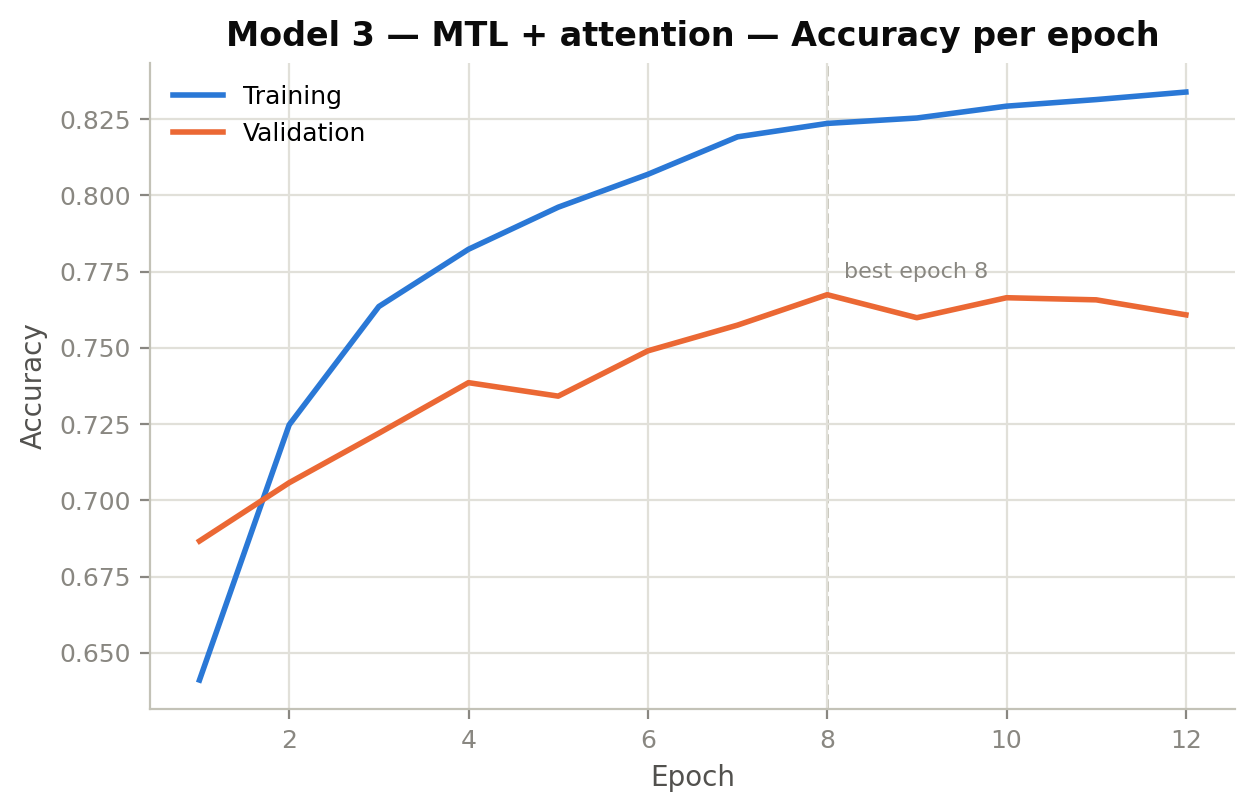

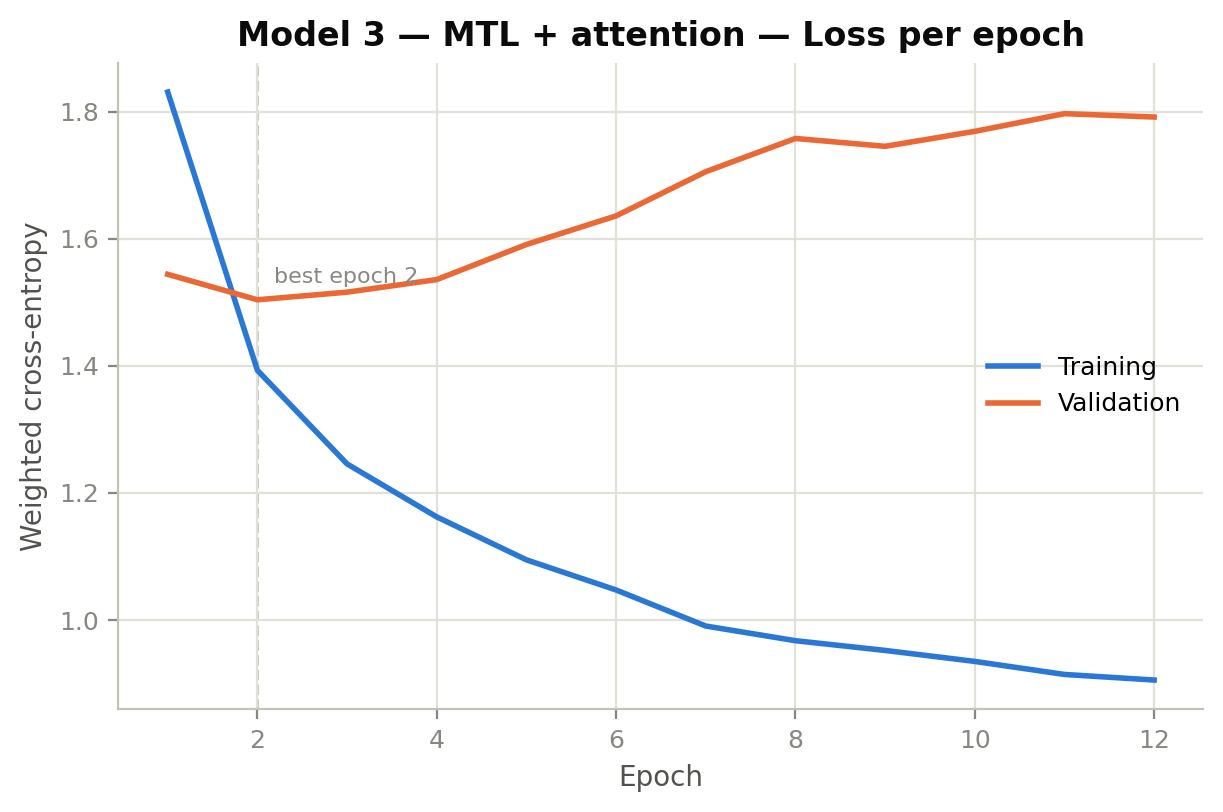

In [8]:
acc_png  = plots.plot_accuracy(hist, NAME, "Model 3 — MTL + attention")
loss_png = plots.plot_loss(hist,  NAME, "Model 3 — MTL + attention")
display(Image(acc_png)); display(Image(loss_png))

The loss plotted is the **combined four-head objective**, so its scale is not comparable with
Models 1 and 2. Notebook `04` plots Model 3's pit-head component instead when putting the three
side by side.

## 8. Results and confusion matrix

In [9]:
threshold, val_f1 = M.tune_threshold(y_val, val_prob)
baseline   = M.majority_baseline(y_test)
test_tuned = M.compute(y_test, test_prob, threshold)
test_def   = M.compute(y_test, test_prob, 0.5)
print(f"tuned threshold: {threshold:.3f} (validation F1 {val_f1:.4f})")

pd.DataFrame([
    {"model": "Never-pit baseline", **{k: baseline[k]   for k in ("accuracy","balanced_accuracy","precision","recall","f1","roc_auc","pr_auc")}},
    {"model": "Model 3 @ 0.50",     **{k: test_def[k]   for k in ("accuracy","balanced_accuracy","precision","recall","f1","roc_auc","pr_auc")}},
    {"model": "Model 3 @ tuned",    **{k: test_tuned[k] for k in ("accuracy","balanced_accuracy","precision","recall","f1","roc_auc","pr_auc")}},
]).set_index("model").round(4)

tuned threshold: 0.708 (validation F1 0.3630)


,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,
Never-pit baseline,0.9148,0.5000,0.0000,0.0000,0.0000,0.5000,0.0852
Model 3 @ 0.50,0.6944,0.6967,0.1755,0.6996,0.2806,0.7555,0.2650
Model 3 @ tuned,0.8177,0.6732,0.2334,0.4989,0.3181,0.7555,0.2650


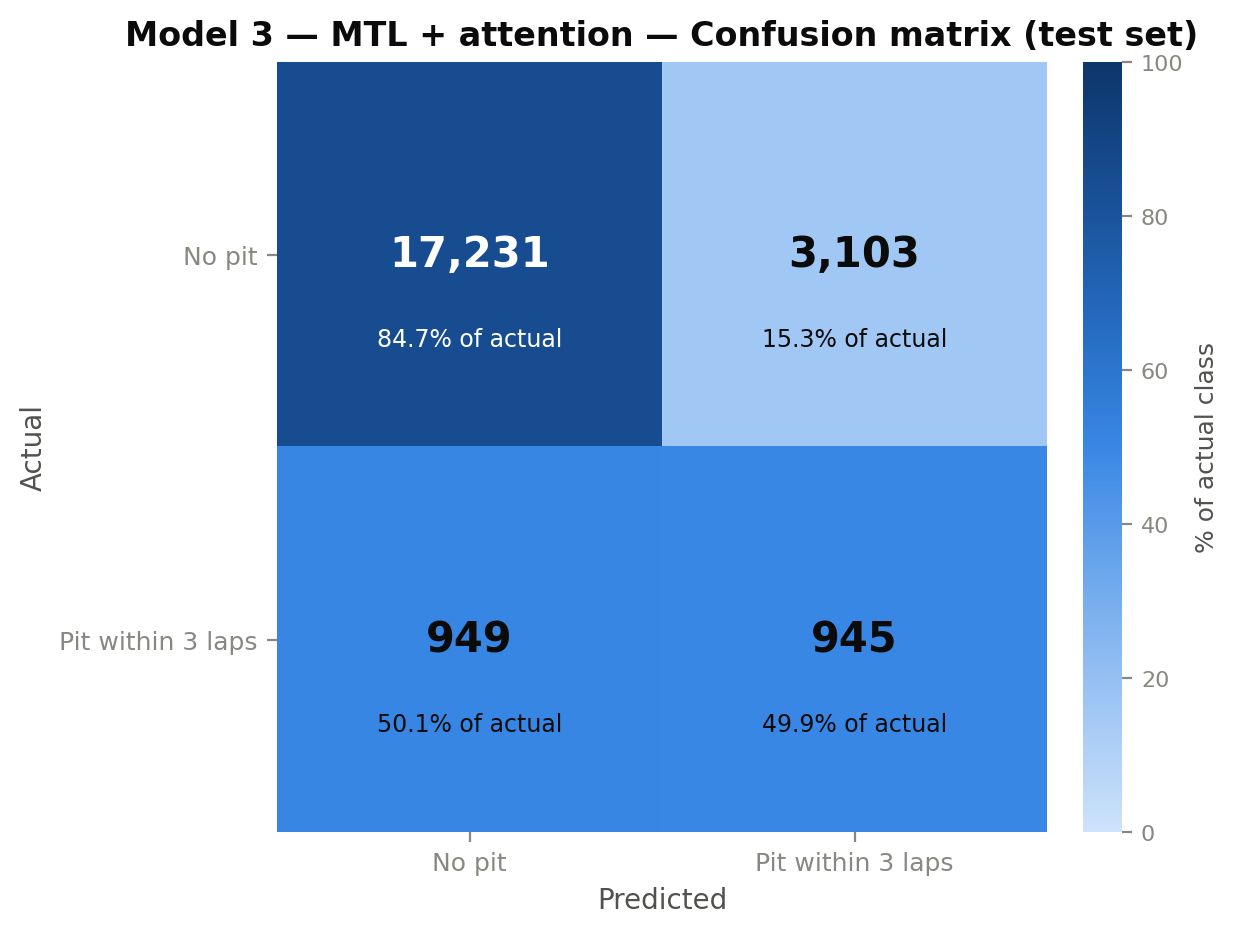

In [10]:
display(Image(plots.plot_confusion_matrix(np.array(test_tuned["confusion_matrix"]), NAME,
                                          "Model 3 — MTL + attention")))

## 9. Ablation — does cross-driver attention earn its place?

A width sweep would say which Model 3 is best. It would **not** answer the question the project is
actually asking. So the sweep is a 2×2: attention on/off crossed with multi-task on/off, plus two
width variants. Selection on validation PR-AUC, as for Models 1 and 2.

`use_attention=False` removes the attention sub-block **and nothing else** — encoder,
feed-forward block, normalisations and all four heads are untouched. It is the only honest way to
attribute a score difference to the cross-driver mechanism rather than to the extra depth that
arrives with it.

Reproduce with `python scripts/ablate_model3.py` (about 10 minutes).

In [11]:
abl = pd.read_csv(config.METRICS_DIR / "mtl_ablation.csv")
abl[["config","description","attention","multi_task","params","val_pr_auc","test_pr_auc","test_roc_auc"]]

,config,description,attention,multi_task,params,val_pr_auc,test_pr_auc,test_roc_auc
0,A,attn + multi-task (full Model 3),True,True,48394,0.2936,0.2650,0.7555
1,B,attn + pit only,True,False,48394,0.3007,0.2804,0.7536
2,C,no attn + multi-task,False,True,31754,0.3122,0.3119,0.7852
3,D,no attn + pit only (control),False,False,31754,0.3112,0.3079,0.7843
4,E,"attn + multi-task, wider",True,True,162314,0.2769,0.2870,0.7914
5,F,"attn + multi-task, narrower",True,True,13914,0.2682,0.2872,0.7616


In [12]:
A = {r["config"]: r for _, r in abl.iterrows()}
pd.DataFrame([
    {"effect": "Attention, with multi-task", "comparison": "A vs C", "delta test PR-AUC": A["A"]["test_pr_auc"]-A["C"]["test_pr_auc"]},
    {"effect": "Attention, pit head only",   "comparison": "B vs D", "delta test PR-AUC": A["B"]["test_pr_auc"]-A["D"]["test_pr_auc"]},
    {"effect": "Multi-task, with attention", "comparison": "A vs B", "delta test PR-AUC": A["A"]["test_pr_auc"]-A["B"]["test_pr_auc"]},
    {"effect": "Multi-task, no attention",   "comparison": "C vs D", "delta test PR-AUC": A["C"]["test_pr_auc"]-A["D"]["test_pr_auc"]},
]).set_index("effect").round(4)

,comparison,delta test PR-AUC
effect,,
"Attention, with multi-task",A vs C,-0.0469
"Attention, pit head only",B vs D,-0.0275
"Multi-task, with attention",A vs B,-0.0154
"Multi-task, no attention",C vs D,0.0040


### The finding is negative, and consistent

**Cross-driver attention costs performance in both conditions** — with and without the auxiliary
heads. Multi-task learning is roughly neutral. The best configuration in the whole grid is the one
with no attention at all.

Two candidate explanations, both testable:

* **The grid layout collapses the training signal.** Regrouping by `(race, lap)` turns 38,890
  training windows into 2,181 grids — roughly 18× fewer gradient updates per epoch, just as
  attention adds parameters.
* **The competitor context is already in the features.** Gap to leader, intervals ahead and
  behind, share of the field stopped, and tyre age relative to the field are all engineered into
  the 55 inputs. Attention may be relearning, noisily and from far fewer examples, what those
  features already state directly.

Model 3's reported row stays configuration **A**, the architecture as proposed. C and D are
ablation *controls*, not candidate configurations: switching attention off changes what the model
is, unlike the width sweeps that selected Models 1 and 2. Reporting C as "Model 3" would mislabel
the architecture and bury the result.

A controlled negative result about a specific mechanism on a specific dataset is a more defensible
contribution than an unsupported positive claim.

Next: the three-model comparison and the race replay, in notebook `04`.